<a href="https://colab.research.google.com/github/Mandita01/BANCO-DADOS/blob/Mandita01-patch-1/Sorveteria.Untitled0.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("sakshisatre/ice-cream-sales-dataset")

print("Path to dataset files:", path)


100%|██████████| 2.09k/2.09k [00:00<00:00, 4.04MB/s]

Extracting files...
Path to dataset files: /root/.cache/kagglehub/datasets/sakshisatre/ice-cream-sales-dataset/versions/1


In [ ]:
import os
import pandas as pd

# Listar os arquivos na pasta do dataset para encontrar o CSV
files = os.listdir(path)
print("Arquivos encontrados:", files)

# Filtrar pelo arquivo CSV
csv_files = [f for f in files if f.endswith('.csv')]
if csv_files:
    csv_path = os.path.join(path, csv_files[0])
    df = pd.read_csv(csv_path)
    print(f"DataFrame carregado com sucesso a partir de: {csv_files[0]}")
    display(df.head())
else:
    print("Nenhum arquivo CSV encontrado no diretório.")

Arquivos encontrados: ['Ice Cream.csv']
DataFrame carregado com sucesso a partir de: Ice Cream.csv


,Temperature,Revenue
0,24.6,535
1,26.1,626
2,27.8,661
3,20.6,488
4,11.6,317


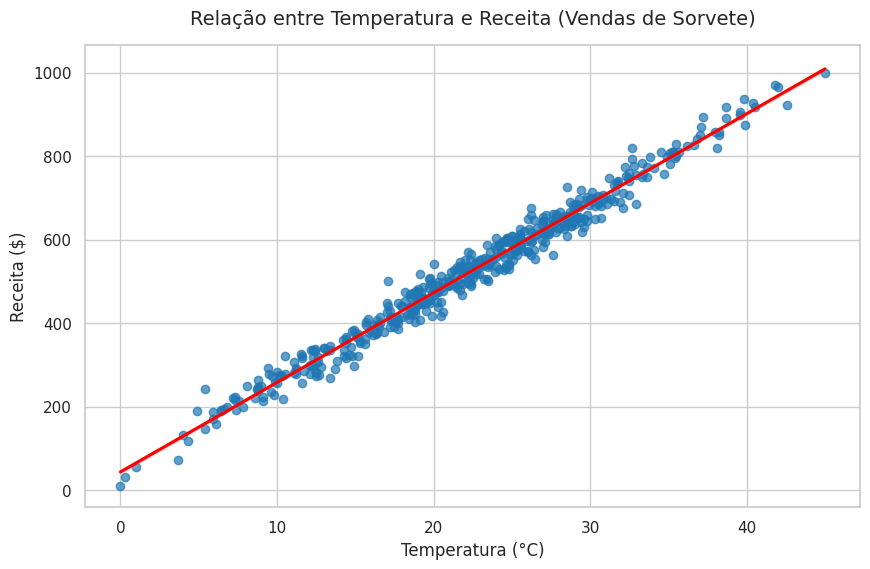

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Configurar o estilo do gráfico
sns.set_theme(style="whitegrid")

# Criar a figura
plt.figure(figsize=(10, 6))

# Criar o gráfico de dispersão com uma linha de tendência (regressão)
sns.regplot(data=df, x="Temperature", y="Revenue", scatter_kws={"alpha":0.7, "color": "#1f77b4"}, line_kws={"color": "red"})

# Adicionar títulos e rótulos
plt.title("Relação entre Temperatura e Receita (Vendas de Sorvete)", fontsize=14, pad=15)
plt.xlabel("Temperatura (°C)", fontsize=12)
plt.ylabel("Receita ($)", fontsize=12)

# Exibir o gráfico
plt.show()

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn import metrics
import numpy as np

# 1. Preparar as variáveis independentes (X) e dependentes (y)
X = df[['Temperature']]
y = df['Revenue']

# 2. Dividir o dataset em treino (80%) e teste (20%)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 3. Criar e treinar o modelo de Regressão Linear
modelo = LinearRegression()
modelo.fit(X_train, y_train)

# 4. Fazer previsões no conjunto de teste
y_pred = modelo.predict(X_test)

# 5. Avaliar e exibir as métricas do modelo
r2 = metrics.r2_score(y_test, y_pred)
mae = metrics.mean_absolute_error(y_test, y_pred)
mse = metrics.mean_squared_error(y_test, y_pred)

print("=== Métricas do Modelo ===")
print(f"Coeficiente (Inclinação - Slope): {modelo.coef_[0]:.4f}")
print(f"Intercepto (Viés - Intercept): {modelo.intercept_:.4f}")
print(f"R² Score (Coeficiente de Determinação): {r2:.4f}")
print(f"Erro Médio Absoluto (MAE): {mae:.4f}")
print(f"Erro Quadrático Médio (MSE): {mse:.4f}")
print("=========================")

# Exemplo prático de previsão
temp_exemplo = 30
previsao = modelo.predict([[temp_exemplo]])[0]
print(f"Previsão de Receita para {temp_exemplo}°C: ${previsao:.2f}")

=== Métricas do Modelo ===
Coeficiente (Inclinação - Slope): 21.3840
Intercepto (Viés - Intercept): 46.1783
R² Score (Coeficiente de Determinação): 0.9772
Erro Médio Absoluto (MAE): 19.1957
Erro Quadrático Médio (MSE): 652.4938
Previsão de Receita para 30°C: $687.70


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(
